# 04 Stabilita v čase: drží odhad shodu s referenční rekonstrukcí a je během výboje hladký?

**Otázka (REQ-003).** Jak velká je chyba každého parametru tvaru a mění se během vývoje
plazmatu? Je výstup z jednoho okamžiku na druhý stabilní, nebo skáče? Kde model selhává? Výsledky platí pro základní síť a čisté vstupy; protějšek se zašuměnými vstupy je v notebooku 08.

Doba běhu: asi 1 min (2 vlákna CPU); potřebuje surová data a `out/predictions.csv` a `out/stability-over-time.json` (vytvoří je `analysis/run_analyses.py`).

Predikce jsou ty mimo učicí sadu, které zapsal `analysis/out_of_fold.py` (`out/predictions.csv`): každý řádek
odhaduje síť natrénovaná na jiných výbojích (5 foldů po výbojích, 60 epoch). Referenční hodnoty (rekonstrukce ústavu) se načtou zpět z dat. Tabulku po decilech a čísla o chvění uložil také `analysis/stability_over_time.py` (`out/stability-over-time.json`);
tento notebook je přepočítá, ověří, že se shodují, a přidá nové lehké analýzy (struktura chyby, přechody,
rychlost změny, test kauzálního vyhlazení).

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data: HACKATHON_HOME, jinak samotný repozitář, pokud má složku data/, jinak nadřazená složka repozitáře.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "common.py").exists()), None)
if repo is None:
    raise SystemExit("Spusťte z vnitřku repozitáře")
os.environ.setdefault("HACKATHON_HOME", str(repo if (repo / "data").is_dir() else repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("složka se surovými daty nalezena:", C.DATA.exists(), "| složka s výsledky nalezena:", C.OUT.exists())

složka se surovými daty nalezena: True | složka s výsledky nalezena: True


## 1. Načtení predikcí mimo učicí sadu a jejich ohodnocení

In [2]:
df, X, Y, G, M = C.load()
J = {t: i for i, t in enumerate(C.TARGETS)}
pr = pd.read_csv(C.OUT / "predictions.csv")
assert np.array_equal(pr.discharge.values, df.discharge.values) and np.allclose(pr.time.values, df.time.values), "řádky se liší"
P = pr[[f"{t}_pred" for t in C.TARGETS]].values.astype(np.float64)
Y64 = Y.astype(np.float64)
KEY = {}
res = C.score(P, Y, M)
rows = [dict(target=t, unit=res[t]["unit"] or "-", MAE=res[t]["mae"], R2=res[t]["r2"], nRMSE=res[t]["nrmse"]) for t in C.TARGETS]
print("souhrnné skóre mimo učicí sadu přes všech 42972 řádků")
print(pd.DataFrame(rows).set_index("target").round(4).to_string())
print("přesnost is_limited:", round(res["is_limited"]["accuracy"], 4))
KEY["pooled_mae"] = {t: round(res[t]["mae"], 5) for t in C.TARGETS}
KEY["is_limited_accuracy"] = round(res["is_limited"]["accuracy"], 4)

souhrnné skóre mimo učicí sadu přes všech 42972 řádků
                    unit      MAE      R2   nRMSE
target                                           
plasma_current        kA   1.4873  0.9991  0.0297
R_mag_axis            mm   0.3770  0.9757  0.1559
Z_mag_axis            mm   0.3914  0.9845  0.1246
elongation             -   0.0057  0.9982  0.0429
triangularity          -   0.0028  0.9973  0.0517
triangularity_upper    -   0.0030  0.9931  0.0828
triangularity_lower    -   0.0037  0.9977  0.0477
R_x_point             mm   0.2030  0.9940  0.0775
Z_x_point             mm   0.1956  0.9983  0.0408
R_strike_point_1      mm   0.2649  0.9957  0.0654
Z_strike_point_1      mm   0.1311  0.9933  0.0818
R_strike_point_2      mm   0.2295  0.9977  0.0478
Z_strike_point_2      mm   0.0557  0.9950  0.0705
R_limiter             mm  10.8063  0.8988  0.3181
Z_limiter             mm  22.2519  0.9253  0.2734
is_limited             -   0.0203  0.9792  0.1443
přesnost is_limited: 0.9926


## 2. Chyba podle relativního času výboje

`time` běží v každém výboji od 0 do 1. Rozdělíme ho na desetiny a v každé uvedeme průměrnou absolutní chybu.

                    unit   0-10 %  10-20 %  20-30 %  30-40 %  40-50 %  50-60 %  60-70 %  70-80 %  80-90 %  90-100 %
plasma_current        kA   1.2419   1.3344   1.5219   1.2018   1.2366   1.2383   1.3423   1.4983   1.8912    2.3544
R_mag_axis            mm   0.5983   0.2759   0.2852   0.2586   0.2395   0.2359   0.2318   0.2860   0.4461    0.8999
Z_mag_axis            mm   0.4567   0.2610   0.3561   0.2958   0.2943   0.3000   0.2973   0.3331   0.4624    0.8483
elongation             -   0.0045   0.0063   0.0073   0.0052   0.0040   0.0038   0.0040   0.0043   0.0072    0.0101
triangularity          -   0.0024   0.0030   0.0031   0.0022   0.0021   0.0020   0.0020   0.0023   0.0038    0.0054
triangularity_upper    -   0.0021   0.0027   0.0030   0.0027   0.0027   0.0027   0.0028   0.0031   0.0035    0.0045
triangularity_lower    -   0.0034   0.0040   0.0040   0.0026   0.0024   0.0024   0.0024   0.0027   0.0051    0.0077
R_x_point             mm      NaN   0.3221   0.1857   0.1534   0.1487   

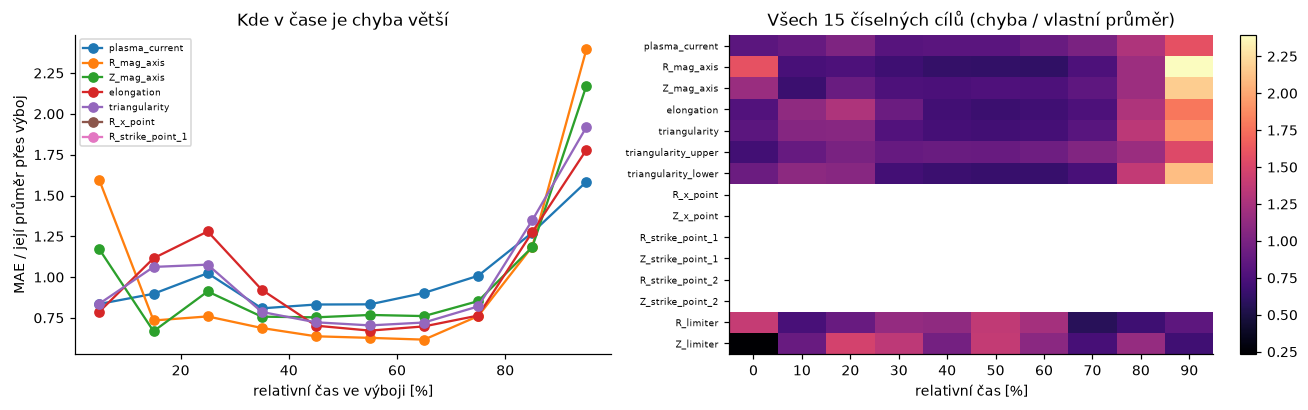

In [3]:
bins = np.minimum((df.time.values * 10).astype(int), 9)
NUM = [t for t in C.TARGETS if t != "is_limited"]
dec = {}
for t in NUM:
    j = J[t]; scale, unit = C.UNIT[t]; k = M[:, j]
    err = np.abs(P[:, j] - Y64[:, j]) * scale
    dec[t] = np.array([err[k & (bins == b)].mean() if (k & (bins == b)).any() else np.nan for b in range(10)])  # NaN: cíl v té desetině neexistuje
dec_tab = pd.DataFrame(dec, index=[f"{b * 10}-{b * 10 + 10} %" for b in range(10)]).T
dec_tab.insert(0, "unit", [C.UNIT[t][1] or "-" for t in NUM])
print(dec_tab.round(4).to_string())

saved_time = json.load(open(C.OUT / "stability-over-time.json"))
rel = [abs(dec[t][b] / saved_time["mae_by_time_decile"][t][b] - 1) for t in dec for b in range(10) if not np.isnan(dec[t][b])]
KEY["agreement_with_saved_time_json_max_relative_diff"] = float(max(rel))
print("\nnejvětší relativní rozdíl proti out/stability-over-time.json:", f"{max(rel):.2e}")

KEY_T = ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "triangularity", "R_x_point", "R_strike_point_1"]
mid = {t: float(dec[t][3:7].mean()) for t in KEY_T}  # 30 až 70 % výboje
first_over_middle = {t: float(dec[t][0] / mid[t]) for t in KEY_T}  # NaN tam, kde cíl v první desetině neexistuje
last_over_middle = {t: float(dec[t][9] / mid[t]) for t in KEY_T}
KEY["first_over_middle_error_ratio"] = {t: None if np.isnan(v) else round(v, 3) for t, v in first_over_middle.items()}
KEY["last_over_middle_error_ratio"] = {t: round(v, 3) for t, v in last_over_middle.items()}
KEY["first_decile_last_decile_middle_mae"] = {t: [None if np.isnan(dec[t][0]) else round(float(dec[t][0]), 4), round(float(dec[t][9]), 4), round(float(mid[t]), 4)] for t in KEY_T}
print("chyba v první desetině dělená průměrnou chybou v 30 až 70 % výboje:", KEY["first_over_middle_error_ratio"])
print("chyba v poslední desetině dělená průměrnou chybou v 30 až 70 % výboje:", KEY["last_over_middle_error_ratio"])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for t in KEY_T:
    ax[0].plot(np.arange(10) * 10 + 5, dec[t] / dec[t].mean(), marker="o", label=t)
ax[0].set_xlabel("relativní čas ve výboji [%]"); ax[0].set_ylabel("MAE / její průměr přes výboj"); ax[0].legend(fontsize=6)
ax[0].set_title("Kde v čase je chyba větší")
im = ax[1].imshow(np.array([dec[t] / dec[t].mean() for t in NUM]), aspect="auto", cmap="magma")
ax[1].set_yticks(range(len(NUM))); ax[1].set_yticklabels(NUM, fontsize=6); ax[1].set_xticks(range(10)); ax[1].set_xticklabels([f"{b * 10}" for b in range(10)])
ax[1].set_xlabel("relativní čas [%]"); ax[1].set_title("Všech 15 číselných cílů (chyba / vlastní průměr)"); fig.colorbar(im, ax=ax[1], fraction=0.046)
fig.tight_layout(); plt.show()

## 3. Hladkost z jednoho okamžiku na druhý a posuny celých výbojů

*Poměr chvění* (jitter ratio) = RMS změny predikce z řádku na řádek dělené stejnou veličinou pro referenční hodnoty (1 znamená stejnou hladkost;
používají se jen dvojice řádků bližší než 0,01 relativního času). *Podíl posunu* (offset share) = jak velká část čtverce chyby je konstantní
posun celého výboje a ne šum z řádku na řádek.

In [4]:
srt = df.sort_values(["discharge", "time"])
idx = srt.index.values
dis, tm = G[idx], df.time.values[idx]
dense = (dis[1:] == dis[:-1]) & (np.diff(tm) < 0.01)
jit, off = {}, {}
for t in NUM:
    j = J[t]; k = M[:, j]
    ok = dense & k[idx[1:]] & k[idx[:-1]]
    dp, dt = np.diff(P[idx, j])[ok], np.diff(Y64[idx, j])[ok]
    jit[t] = float(np.sqrt(np.mean(dp ** 2)) / np.sqrt(np.mean(dt ** 2)))
    err = P[:, j] - Y64[:, j]
    per = pd.Series(err[k]).groupby(G[k])
    off[t] = float((per.mean() ** 2 * per.size()).sum() / (err[k] ** 2).sum())
cmp_tab = pd.DataFrame({"jitter_ratio": jit, "offset_share": off, "saved_jitter": {t: saved_time["jitter_ratio"].get(t, np.nan) for t in NUM}, "saved_offset": {t: saved_time["bias_share"].get(t, np.nan) for t in NUM}})
print(cmp_tab.round(4).to_string())
KEY["jitter_ratio"] = {t: round(v, 3) for t, v in jit.items()}
KEY["offset_share"] = {t: round(v, 3) for t, v in off.items()}
KEY["jitter_offset_max_abs_diff_to_saved"] = float(max(np.nanmax(np.abs(cmp_tab.jitter_ratio - cmp_tab.saved_jitter)), np.nanmax(np.abs(cmp_tab.offset_share - cmp_tab.saved_offset))))
print("podíl dvojic po sobě jdoucích řádků, které jsou dost blízko:", round(float(dense.mean()), 3))
KEY["dense_pair_share"] = round(float(dense.mean()), 3)

                     jitter_ratio  offset_share  saved_jitter  saved_offset
plasma_current             1.0735        0.3049        1.0735        0.3049
R_mag_axis                 0.9704        0.0958        0.9704        0.0958
Z_mag_axis                 1.0630        0.0546        1.0630        0.0546
elongation                 1.0305        0.1276        1.0305        0.1276
triangularity              1.0490        0.1370        1.0490        0.1370
triangularity_upper        1.0066        0.2302        1.0066        0.2302
triangularity_lower        1.0058        0.1222        1.0058        0.1222
R_x_point                  0.9995        0.6225        0.9995        0.6225
Z_x_point                  1.0054        0.6790        1.0054        0.6790
R_strike_point_1           1.0022        0.8151        1.0022        0.8151
Z_strike_point_1           0.9941        0.6501        0.9941        0.6501
R_strike_point_2           0.9881        0.4800        0.9881        0.4800
Z_strike_poi

## 4. Chyba pomalu bloudí, nebo bliká? (autokorelace chyby uvnitř výboje)

průměrná autokorelace chyby mezi řádky vzdálenými `lag`, uvnitř jednoho výboje
             R_mag_axis  elongation  plasma_current
lag 1 rows        0.686       0.807           0.854
lag 2 rows        0.567       0.644           0.756
lag 5 rows        0.321       0.384           0.496
lag 10 rows       0.150       0.161           0.259
lag 20 rows       0.064       0.081           0.091
lag 50 rows      -0.012      -0.053           0.009


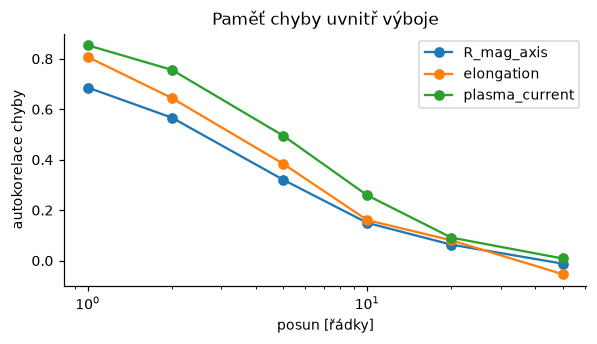

In [5]:
lags = [1, 2, 5, 10, 20, 50]
groups = srt.groupby("discharge").indices
acf = {}
for t in ("R_mag_axis", "elongation", "plasma_current"):
    j = J[t]
    e_sorted = (P[idx, j] - Y64[idx, j])
    acf[t] = []
    for lag in lags:
        cs = []
        for g_, ii in groups.items():
            if len(ii) > lag + 20:
                a, b = e_sorted[ii][:-lag], e_sorted[ii][lag:]
                if a.std() > 0 and b.std() > 0:
                    cs.append(np.corrcoef(a, b)[0, 1])
        acf[t].append(float(np.mean(cs)))
acf_tab = pd.DataFrame(acf, index=[f"lag {l} rows" for l in lags])
print("průměrná autokorelace chyby mezi řádky vzdálenými `lag`, uvnitř jednoho výboje")
print(acf_tab.round(3).to_string())
KEY["error_autocorrelation"] = {t: {str(l): round(v, 3) for l, v in zip(lags, acf[t])} for t in acf}
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for t in acf:
    ax.plot(lags, acf[t], marker="o", label=t)
ax.set_xscale("log"); ax.set_xlabel("posun [řádky]"); ax.set_ylabel("autokorelace chyby"); ax.legend(); ax.set_title("Paměť chyby uvnitř výboje")
fig.tight_layout(); plt.show()

## 5. Výboj po výboji: je model všude stejně dobrý?

               unit  median     p90     p95    worst  worst_over_median
target                                                                 
R_mag_axis       mm  0.2361  0.8142  1.4849   6.8057            28.8198
elongation        -  0.0042  0.0104  0.0145   0.0353             8.3264
plasma_current   kA  1.0376  2.6397  3.8897  18.6697            17.9933
tři nejhorší výboje pro R_mag_axis (číslo, MAE mm, řádků): [(148, 6.81, 44), (127, 4.84, 131), (7, 4.13, 37)]
Spearman mezi MAE R_mag_axis výboje a jeho počtem řádků: -0.287


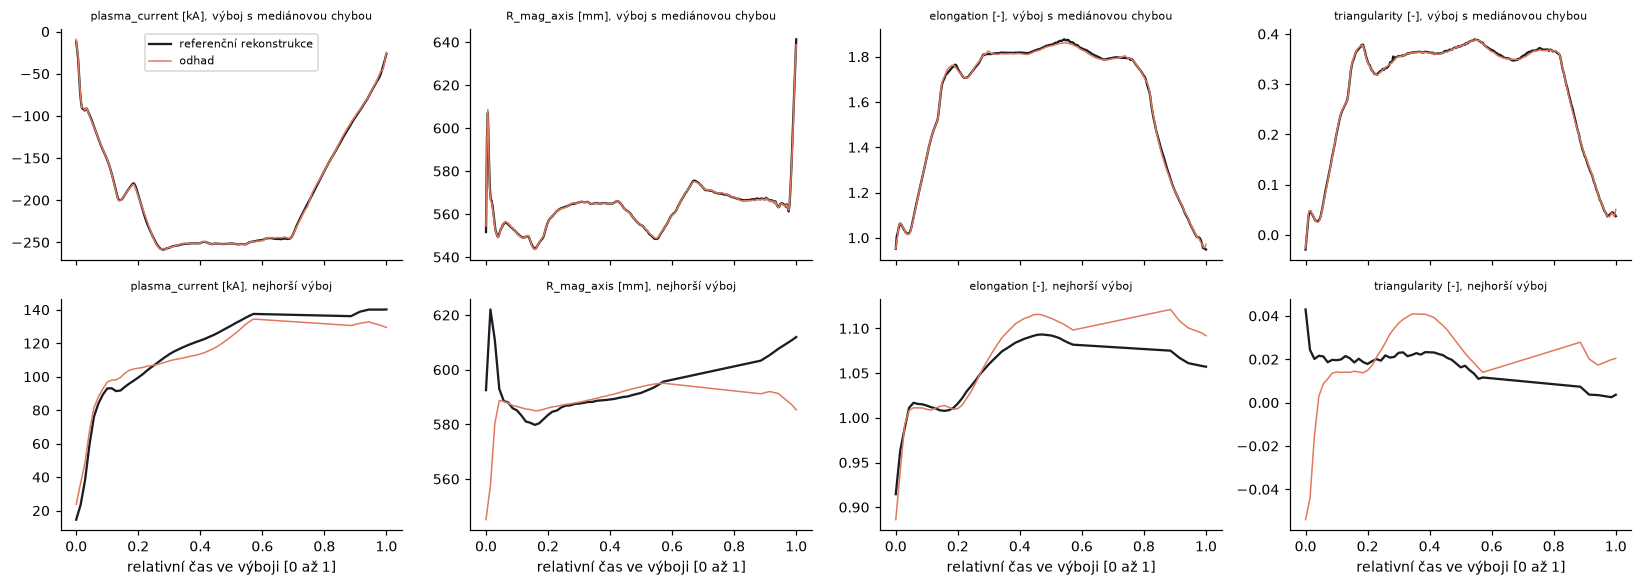

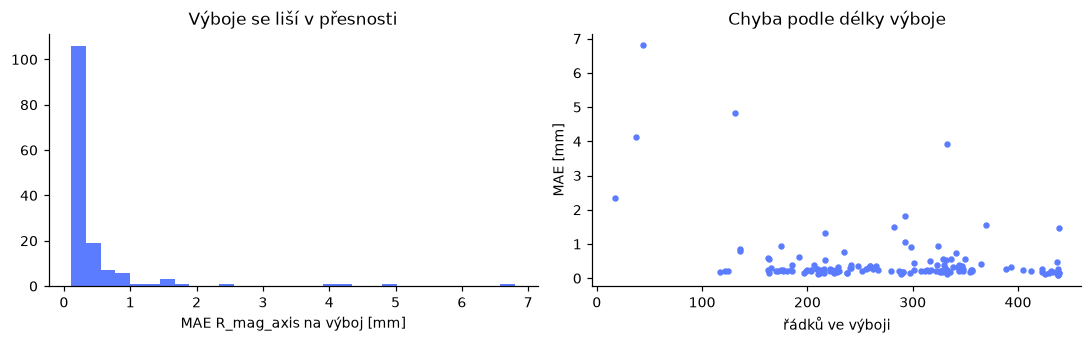

In [6]:
n_rows = df.groupby("discharge").size()
pd_mae = {}
for t in ("R_mag_axis", "elongation", "plasma_current"):
    j = J[t]; scale, unit = C.UNIT[t]
    pd_mae[t] = (pd.Series(np.abs(P[:, j] - Y64[:, j]) * scale).groupby(G).mean())
rows = []
for t, s in pd_mae.items():
    rows.append(dict(target=t, unit=C.UNIT[t][1] or "-", median=s.median(), p90=s.quantile(0.9), p95=s.quantile(0.95), worst=s.max(), worst_over_median=s.max() / s.median()))
print(pd.DataFrame(rows).set_index("target").round(4).to_string())
from scipy.stats import spearmanr
s = pd_mae["R_mag_axis"]
sp = spearmanr(s.values, n_rows.loc[s.index].values)
worst3 = s.sort_values(ascending=False).index[:3]
KEY["per_discharge_mae"] = {t: {"median": round(float(v.median()), 4), "p95": round(float(v.quantile(0.95)), 4), "worst": round(float(v.max()), 4)} for t, v in pd_mae.items()}
KEY["corr_discharge_mae_vs_length_R_mag_axis"] = float(sp.statistic)
KEY["worst3_discharges_R_mag_axis"] = {str(g_): {"mae_mm": round(float(s.loc[g_]), 3), "rows": int(n_rows.loc[g_])} for g_ in worst3}
print("tři nejhorší výboje pro R_mag_axis (číslo, MAE mm, řádků):", [(int(g_), round(float(s.loc[g_]), 2), int(n_rows.loc[g_])) for g_ in worst3])
print(f"Spearman mezi MAE R_mag_axis výboje a jeho počtem řádků: {sp.statistic:.3f}")

med_g = s.index[np.argsort(s.values)[len(s) // 2]]
bad_g = worst3[0]
fig, ax = plt.subplots(2, 4, figsize=(15, 5.4), sharex=True)
for r, (g_, lab) in enumerate(((med_g, "výboj s mediánovou chybou"), (bad_g, "nejhorší výboj"))):
    d = df[df.discharge == g_].sort_values("time")
    for a, t in zip(ax[r], ["plasma_current", "R_mag_axis", "elongation", "triangularity"]):
        j = J[t]; scale, unit = C.UNIT[t]
        a.plot(d.time, d[t] * scale, color="#1a1d23", label="referenční rekonstrukce")
        a.plot(d.time, P[d.index.values, j] * scale, color="#e07a5f", label="odhad", lw=1)
        a.set_title(f"{t} [{unit or '-'}], {lab}", fontsize=7)
ax[0, 0].legend(fontsize=7)
for a in ax[1]:
    a.set_xlabel("relativní čas ve výboji [0 až 1]")
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(pd_mae["R_mag_axis"].values, bins=30, color="#5b7cff"); ax[0].set_xlabel("MAE R_mag_axis na výboj [mm]"); ax[0].set_title("Výboje se liší v přesnosti")
ax[1].scatter(n_rows.loc[s.index].values, s.values, s=10, color="#5b7cff"); ax[1].set_xlabel("řádků ve výboji"); ax[1].set_ylabel("MAE [mm]"); ax[1].set_title("Chyba podle délky výboje")
fig.tight_layout(); plt.show()

## 6. Soustřeďuje se chyba kolem přepnutí mezi limiterovým a divertorovým plazmatem?

`is_limited` mění v některých výbojích hodnotu. Pro každý řádek změříme jeho vzdálenost (v řádcích) k nejbližšímu přepnutí
v témže výboji a chyby porovnáme podle vzdálenosti.

In [7]:
lim_sorted = (Y[idx, J["is_limited"]] > 0.5)
dist = np.full(len(idx), 10 ** 6)
n_switch, n_dis_switch = 0, 0
for g_, ii in groups.items():
    ls = lim_sorted[ii]
    sw = np.nonzero(ls[1:] != ls[:-1])[0] + 1
    if len(sw):
        n_switch += len(sw); n_dis_switch += 1
        pos = np.arange(len(ii))
        d_ = np.min(np.abs(pos[:, None] - sw[None, :]), axis=1)
        dist[ii] = d_
KEY["limited_switches"] = {"switches": int(n_switch), "discharges_with_a_switch": int(n_dis_switch)}
print(f"{n_switch} přepnutí is_limited uvnitř {n_dis_switch} ze 149 výbojů")
edges_ = [(0, 3), (4, 10), (11, 30), (31, 10 ** 5)]
mis_sorted = ((P[idx, J["is_limited"]] > 0.5) != lim_sorted)
rows = []
for lo, hi in edges_:
    sel = (dist >= lo) & (dist <= hi) & (dist < 10 ** 6) if hi < 10 ** 5 else (dist >= lo)  # poslední skupina obsahuje i řádky výbojů bez přepnutí
    row = dict(distance_rows=f"{lo}-{hi}" if hi < 10 ** 5 else f">{lo - 1} nebo bez přepnutí", rows=int(sel.sum()), is_limited_wrong_share=float(mis_sorted[sel].mean()))
    for t in ("R_mag_axis", "elongation", "plasma_current"):
        j = J[t]; scale, unit = C.UNIT[t]
        e = np.abs(P[idx, j] - Y64[idx, j]) * scale
        row[f"MAE_{t}"] = float(np.nanmean(e[sel]))
    rows.append(row)
sw_tab = pd.DataFrame(rows).set_index("distance_rows")
print(sw_tab.round(4).to_string())
KEY["error_by_distance_to_switch"] = {i: {k: round(float(v), 4) for k, v in r.items()} for i, r in sw_tab.iterrows()}
KEY["share_of_all_is_limited_errors_within_3_rows_of_a_switch"] = float(mis_sorted[(dist <= 3)].sum() / max(mis_sorted.sum(), 1))
print("podíl všech špatně určených řádků, které leží do 3 řádků od přepnutí:", round(KEY["share_of_all_is_limited_errors_within_3_rows_of_a_switch"], 3))

456 přepnutí is_limited uvnitř 137 ze 149 výbojů
                        rows  is_limited_wrong_share  MAE_R_mag_axis  MAE_elongation  MAE_plasma_current
distance_rows                                                                                           
0-3                     1991                  0.1592          0.3975          0.0090              2.1045
4-10                    3354                  0.0003          0.3443          0.0072              1.5950
11-30                   9343                  0.0000          0.3390          0.0064              1.4490
>30 nebo bez přepnutí  28284                  0.0000          0.3920          0.0050              1.4437
podíl všech špatně určených řádků, které leží do 3 řádků od přepnutí: 0.994


## 7. Je chyba větší tam, kde se plazma rychle mění?

Rychlost změny = |změna referenční hodnoty mezi dvěma sousedními řádky| / změna relativního času (jednotka: jednotka cíle na jednotku relativního času; čas v sekundách mezi řádky v souboru není). Řádky se
podle rychlosti rozřežou na čtyři stejně velké skupiny; chyba je chyba v prvním řádku dvojice.

In [8]:
same = (dis[1:] == dis[:-1]) & (np.diff(tm) > 0)
speed_tab = {}
KEY["error_by_speed_quartile"] = {}
for t in ("R_mag_axis", "elongation", "plasma_current"):
    j = J[t]; scale, unit = C.UNIT[t]
    ok = same & M[idx[1:], j] & M[idx[:-1], j]
    spd = np.abs(np.diff(Y64[idx, j]))[ok] / np.diff(tm)[ok] * scale
    e = (np.abs(P[idx, j] - Y64[idx, j]) * scale)[:-1][ok]
    q = np.quantile(spd, [0.25, 0.5, 0.75])
    qb = np.digitize(spd, q)
    speed_tab[t] = [float(e[qb == i].mean()) for i in range(4)]
    KEY["error_by_speed_quartile"][t] = [round(v, 4) for v in speed_tab[t]] + [round(float(spearmanr(spd, e).statistic), 3)]
print("MAE v každém kvartilu rychlosti (nejpomalejší první) a Spearmanova korelace rychlosti a chyby (poslední položka v KEY)")
print(pd.DataFrame(speed_tab, index=["nejpomalejších 25 %", "25-50 %", "50-75 %", "nejrychlejších 25 %"]).round(4).to_string())
print({t: v[-1] for t, v in KEY["error_by_speed_quartile"].items()})

MAE v každém kvartilu rychlosti (nejpomalejší první) a Spearmanova korelace rychlosti a chyby (poslední položka v KEY)
                     R_mag_axis  elongation  plasma_current
nejpomalejších 25 %      0.2784      0.0042          1.3504
25-50 %                  0.3007      0.0045          1.2591
50-75 %                  0.3215      0.0059          1.7714
nejrychlejších 25 %      0.5689      0.0077          1.4819
{'R_mag_axis': 0.144, 'elongation': 0.206, 'plasma_current': 0.165}


## 8. Odstraní kauzální vyhlazení chvění bez újmy?

Regulátor běžící ve smyčce se může dívat jen zpět v čase. Každou predikci nahradíme průměrem posledních w predikcí
téhož výboje (klouzavé okno vzad) a porovnáme chybu s nefiltrovanou.

In [9]:
def trailing_mean(x, w):
    c = np.concatenate([[0.0], np.cumsum(x)])
    n = np.arange(1, len(x) + 1)
    lo = np.maximum(0, n - w)
    return (c[n] - c[lo]) / (n - lo)


smooth_tab = {}
KEY["causal_smoothing_mae_ratio"] = {}
for t in ("R_mag_axis", "elongation", "plasma_current"):
    j = J[t]; scale, unit = C.UNIT[t]
    base_err = float(np.nanmean(np.abs(P[idx, j] - Y64[idx, j])) * scale)
    row = {"unfiltered_MAE": base_err}
    for w in (3, 5, 10, 20):
        ps = np.empty(len(idx))
        for g_, ii in groups.items():
            ps[ii] = trailing_mean(P[idx[ii], j], w)
        row[f"w={w}"] = float(np.nanmean(np.abs(ps - Y64[idx, j])) * scale)
    smooth_tab[t] = row
    KEY["causal_smoothing_mae_ratio"][t] = {k: round(v / base_err, 3) for k, v in row.items() if k != "unfiltered_MAE"}
print("MAE po filtraci klouzavým průměrem vzad s oknem w řádků (stejná jednotka jako dříve)")
print(pd.DataFrame(smooth_tab).T.round(4).to_string())
print("poměr k nefiltrované chybě:", KEY["causal_smoothing_mae_ratio"])

MAE po filtraci klouzavým průměrem vzad s oknem w řádků (stejná jednotka jako dříve)
                unfiltered_MAE     w=3     w=5    w=10    w=20
R_mag_axis              0.3770  0.7660  1.1029  1.6708  2.2952
elongation              0.0057  0.0086  0.0130  0.0237  0.0429
plasma_current          1.4873  2.1446  3.1452  5.6231  9.7931
poměr k nefiltrované chybě: {'R_mag_axis': {'w=3': 2.032, 'w=5': 2.925, 'w=10': 4.431, 'w=20': 6.088}, 'elongation': {'w=3': 1.521, 'w=5': 2.284, 'w=10': 4.167, 'w=20': 7.54}, 'plasma_current': {'w=3': 1.442, 'w=5': 2.115, 'w=10': 3.781, 'w=20': 6.584}}


## Závěry

- **Přesnost na neviděných výbojích (souhrn mimo učicí sadu).** MAE `R_mag_axis` 0,38 mm, `Z_mag_axis` 0,39 mm, proud plazmatu 1,49 kA, elongace 0,0057, `R_x_point` 0,20 mm, `R_strike_point_1` 0,26 mm, bod limiteru 10,8 mm a 22,3 mm a shoda `is_limited` s referenčním příznakem 99,26 %.
- **Chyba roste hlavně na konci výboje.** U `R_mag_axis` je MAE 0,90 mm v poslední desetině proti 0,24 mm uprostřed (30 až 70 % výboje), tedy 3,7krát; u `Z_mag_axis` 2,9krát, u elongace 2,4krát a u proudu plazmatu 1,9krát. Na začátku je horší jen poloha osy (`R_mag_axis` 0,60 mm, 2,5krát, `Z_mag_axis` 1,5krát); X bod a dotykové body v první desetině neexistují. Důvod neznáme; proud plazmatu je tam malý a rychle se mění, takže samotná referenční rekonstrukce tam může být nejméně spolehlivá (hypotéza, netestováno).
- **Na čistých vstupech se výstup mění tak jako referenční hodnoty.** Poměr chvění (1 znamená stejnou změnu z řádku na řádek jako u referenční rekonstrukce) je 0,97 pro `R_mag_axis`, 1,03 pro elongaci a 1,07 pro proud plazmatu, 0,97 až 1,07 pro 7 zobrazených cílů; body limiteru jsou nižší (0,69 a 0,48, `results/stability-over-time.md`). To není tvrzení o zašuměných signálech: s dodanými zašuměnými vstupy se síť natrénovaná na čistých datech mění 8,4krát (radiální osa) a 3,3krát (svislá osa) víc než referenční hodnoty a po učení se šumem a driftem 1,7krát (notebook 08, oddíl 3). Poměr je vážený amplitudou: říká, že síť je hladká, když je hladký její vstup, ne že je robustní. Uložená tabulka v `out/stability-over-time.json` se reprodukuje přesně (největší relativní rozdíl 2e-16).
- **Jak chyba vypadá.** U `R_mag_axis` je jen 10 % čtverce chyby konstantní posun celého výboje, ale u `R_x_point` 62 % a u `R_strike_point_1` 81 %, takže u divertorových bodů je hlavní chybou posun celého výboje. Chyba `R_mag_axis` je mezi sousedními řádky korelovaná (0,69 při posunu o 1, 0,15 při posunu o 10) a po zhruba 20 řádcích zmizí (0,06), je to pomalé bloudění, ne blikání.
- **Na čistých vstupech vyhlazování výstupu v čase nepomáhá.** Kauzální průměr posledních 3 odhadů zvýší chybu na 2,0násobek (`R_mag_axis`), 1,5násobek (elongace) a 1,4násobek (proud plazmatu); s 20 řádky je to 6,1; 7,5 a 6,6násobek, protože výstup sítě má málo chvění k odstranění a filtr přidává zpoždění. U dodaných zašuměných vstupů se obraz mění: když síť dostane na vstup tři po sobě jdoucí řádky, klesne chyba radiální osy z 2,64 na 2,33 mm (notebook 08, oddíl 5). Tady se vyhlazuje výstup, což je něco jiného než časový kontext ve vstupu.
- **Výboje se hodně liší.** Medián MAE `R_mag_axis` na výboj je 0,24 mm, 95. percentil 1,48 mm a nejhorší 6,80 mm (výboj 148, 44 řádků). Kratší výboje bývají horší (Spearman -0,29 mezi chybou a délkou).
- **Chyby v `is_limited` sedí u přepnutí.** Plazma přepíná mezi limiterovým a divertorovým 456krát uvnitř 137 ze 149 výbojů. 99,4 % špatně určených řádků leží do 3 řádků od přepnutí, kde je špatných 15,9 % řádků; chyba elongace je tam 0,0090 proti 0,0050 daleko od přepnutí.
- **Rychlé změny stojí přesnost, u některých cílů.** MAE `R_mag_axis` je 0,28 mm v nejpomalejší čtvrtině řádků a 0,57 mm v nejrychlejší (Spearman 0,14); u proudu plazmatu žádný jasný trend není (1,35 až 1,48 kA).
- **Výhrada.** Všechna čísla pocházejí z jedné sady predikcí mimo učicí sadu (jedno semínko na fold). Závěry jsem opsal z výstupů uloženého běhu a po novém spuštění se mohou mírně lišit.

**Odpověď.** Na čistých vstupech se odhad liší od referenční rekonstrukce zhruba o 0,4 mm v poloze osy, mění se tak jako referenční hodnoty (poměr chvění 0,97 až 1,07 pro 7 zobrazených cílů), je horší na konci výboje (`R_mag_axis` 3,7krát víc než uprostřed) a do 3 řádků od přepnutí mezi limiterovým a divertorovým plazmatem (`is_limited` špatně v 15,9 % těchto řádků, 99,4 % všech jeho chyb). Na dodaných zašuměných vstupech výstup sítě natrénované na čistých datech stabilní není: u radiální osy se mění 8,4krát víc než referenční hodnoty (notebook 08).